# 03 — Viabilidade temporal e auditoria de vazamento

Convenção: dia 0 = início da apresentação; semana *k* = dias 7(k−1)…7k−1; previsão ao fim da semana *k* ⇒ `cutoff_day = 7k − 1`. Só entram eventos com data ≤ corte e estudantes ainda matriculados no corte.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_columns", 30, "display.width", 160)
FIG = ROOT / "research" / "figures"
from src.data.loaders import load_oulad, load_student_vle
from src.feature_engineering import temporal
from src.analysis import eda, leakage
t = load_oulad(); sv = load_student_vle(); base = temporal.student_base(t)
{w: temporal.cutoff_day_for_week(w) for w in (2, 4, 6)}

{2: 13, 4: 27, 6: 41}

## 1. Quando o cancelamento acontece

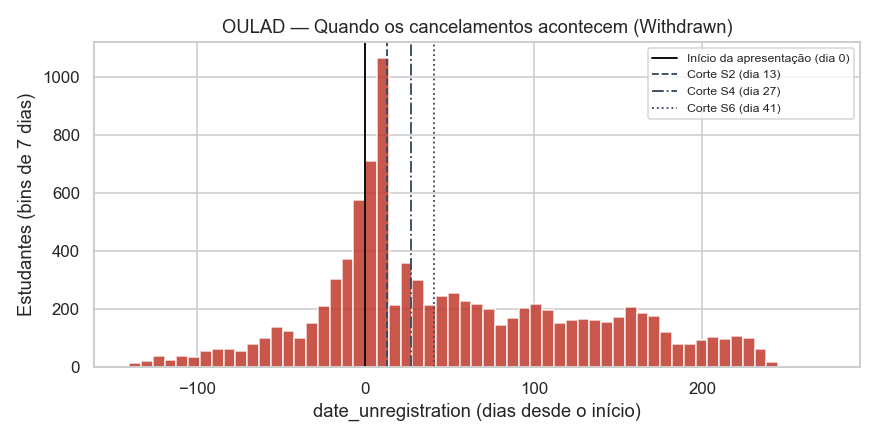

In [2]:
display(Image(FIG / 'oulad_withdrawal_timing.png'))

## 2. População e informação disponível em cada corte

In [3]:
rows = []
snaps = {}
for w in (2, 4, 6):
    c = temporal.cutoff_day_for_week(w)
    s = temporal.snapshot(t, sv, c); snaps[w] = s
    rows.append({'semana': w, 'cutoff_day': c, 'população': len(s),
                 'Withdrawn restantes': int((s['final_result'] == 'Withdrawn').sum()),
                 '% com entrega': round((s['n_submitted'] > 0).mean() * 100, 1),
                 'max data VLE usada': int(sv.loc[sv['date'] <= c, 'date'].max())})
pd.DataFrame(rows)

,semana,cutoff_day,população,Withdrawn restantes,% com entrega,max data VLE usada
0,2,13,28069,5682,10.6,13
1,4,27,27535,5119,71.9,27
2,6,41,27022,4604,82.5,41


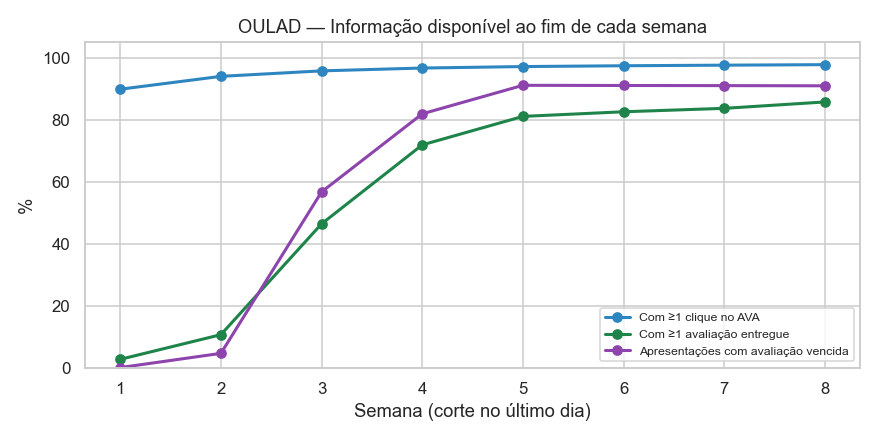

In [4]:
display(Image(FIG / 'oulad_information_availability.png'))

In [5]:
cols = ['total_clicks', 'active_days', 'clicks_last_7_days', 'days_since_last_activity', 'n_submitted', 'mean_score']
for w, s in snaps.items():
    print(f'Semana {w}'); display(s.groupby('final_result')[cols].median())

Semana 2


,total_clicks,active_days,clicks_last_7_days,days_since_last_activity,n_submitted,mean_score
final_result,,,,,,
Distinction,230.0,11.0,64.0,1.0,0.0,87.0
Fail,63.0,5.0,12.0,3.0,0.0,72.0
Pass,151.0,9.0,41.0,1.0,0.0,80.0
Withdrawn,86.0,6.0,19.0,2.0,0.0,73.0


Semana 4


,total_clicks,active_days,clicks_last_7_days,days_since_last_activity,n_submitted,mean_score
final_result,,,,,,
Distinction,389.0,18.0,49.0,1.0,1.0,89.0
Fail,130.0,8.0,9.0,3.0,1.0,70.0
Pass,275.0,15.0,35.0,1.0,1.0,79.0
Withdrawn,180.0,11.0,16.0,2.0,1.0,70.0


Semana 6


,total_clicks,active_days,clicks_last_7_days,days_since_last_activity,n_submitted,mean_score
final_result,,,,,,
Distinction,503.5,25.0,41.0,1.0,1.0,90.0
Fail,162.0,11.0,3.0,4.0,1.0,70.0
Pass,362.0,20.0,28.0,1.0,1.0,80.0
Withdrawn,232.0,14.0,8.0,3.0,1.0,70.5


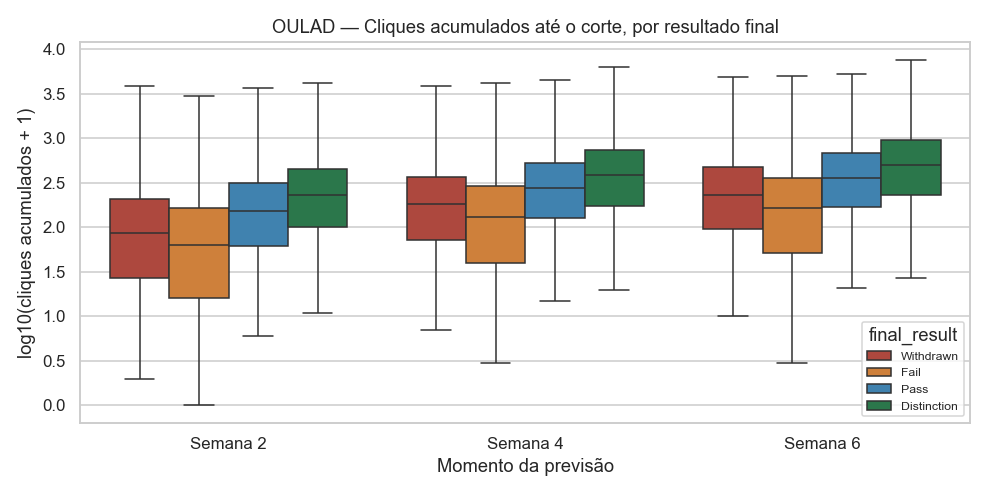

In [6]:
display(Image(FIG / 'oulad_clicks_at_cutoffs.png'))

## 3. Separação univariada (descritiva) vs. referência com vazamento

week_label,Semana 2,Semana 4,Semana 6
indicator,,,
Avaliações entregues,0.0785,0.1327,0.1579
Avaliações vencidas não entregues,0.0064,0.2040,0.2287
Cliques acumulados,0.2721,0.2440,0.2550
Cliques antes do início,0.2074,0.1902,0.1822
Cliques nos últimos 7 dias,0.2513,0.2242,0.3058
Dias ativos,0.2337,0.2424,0.2600
Dias desde o último acesso,0.2084,0.2230,0.2730
Materiais distintos,0.2188,0.1803,0.1718
Nota média (entregues),0.2365,0.3552,0.3878


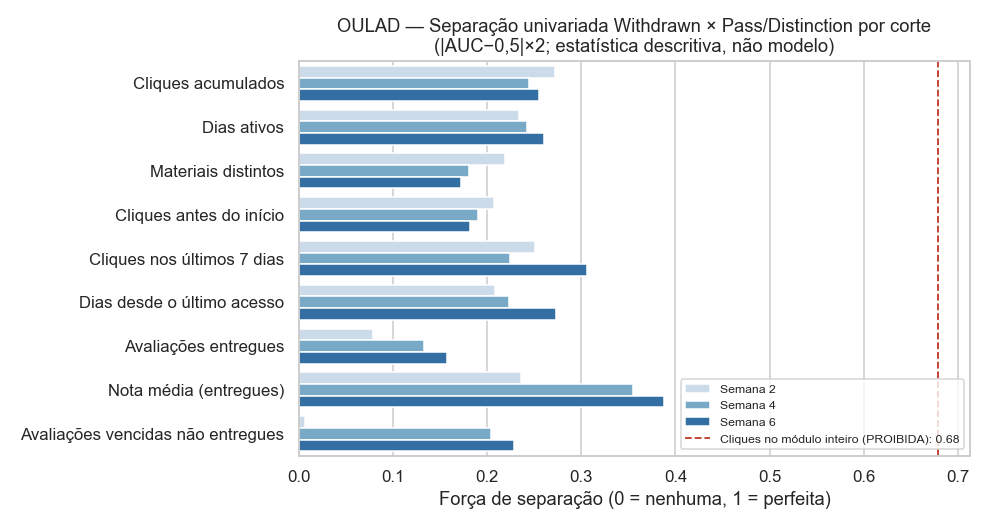

In [7]:
auc = pd.read_csv(ROOT / 'research' / 'inspection' / 'oulad_univariate_separation_by_cutoff.csv')
display(auc.pivot(index='indicator', columns='week_label', values='separation'))
display(Image(FIG / 'oulad_separation_by_cutoff.png'))

A referência **proibida** (agregados do módulo inteiro) separa muito mais — exatamente porque usa o futuro. Ver `docs/DATA_LEAKAGE_AUDIT.md`.

## 4. Catálogo de vazamento

In [8]:
display(leakage.catalog_frame(leakage.OULAD_CATALOG)[['table', 'variable', 'class']])
display(leakage.catalog_frame(leakage.UCI_CATALOG)[['variable', 'class_sem1_weeks_2_6', 'class_sem2_weeks_2_6']])

,table,variable,class
0,studentInfo,code_module / code_presentation,PERMITTED
1,studentInfo,gender,PERMITTED
2,studentInfo,region,PERMITTED
3,studentInfo,highest_education,PERMITTED
4,studentInfo,imd_band,PERMITTED
5,studentInfo,age_band,PERMITTED
6,studentInfo,disability,PERMITTED
7,studentInfo,num_of_prev_attempts,PERMITTED
8,studentInfo,studied_credits,CONDITIONAL
9,studentInfo,final_result,PROHIBITED


,variable,class_sem1_weeks_2_6,class_sem2_weeks_2_6
0,Marital status,PERMITTED,PERMITTED
1,Application mode,PERMITTED,PERMITTED
2,Application order,PERMITTED,PERMITTED
3,Course,PERMITTED,PERMITTED
4,Daytime/evening attendance,PERMITTED,PERMITTED
5,Previous qualification,PERMITTED,PERMITTED
6,Previous qualification (grade),PERMITTED,PERMITTED
7,Nacionality,PERMITTED,PERMITTED
8,Mother's qualification,PERMITTED,PERMITTED
9,Father's qualification,PERMITTED,PERMITTED
